# 🧬 Experiment 13: RosettaCommons Chaperone Workflows & Official Core Examples in SQL
### *Shrake–Rupley RASA, 3D Hydrogen-Bond CSR Networks, BUNS Auditing & Multi-Stage Lineage (`RFdiffusion3 -> Foundry-MPNN -> Boltz-2 / AlphaFold3`)*

[**Chaperone**](https://rosettacommons.org/2026/10/19/introducing-chaperone-a-unified-framework-for-protein-design-workflows/) (`RosettaCommons/chaperone`) and its [8 Official Core Examples](https://rosettacommons.github.io/chaperone/core-examples/) unify modern protein, nucleic acid, and enzyme design into modular, dataframe-in / dataframe-out blocks (`PipelineDataHandler`). In this notebook, we execute Chaperone's entire post-oracle evaluation & lineage pipeline directly inside PostgreSQL 18 using `pg_bio`'s native Rust engine:
1. **Shrake–Rupley 64-Point Fibonacci Sphere SASA & Tien (2013) RASA (`bio_rasa`):** Quantifies solvent exposure, buried interface $\Delta\text{SASA}$, and aggregation-prone hydrophobic surface patches.
2. **3D Hydrogen-Bond CSR Network & BUNS Auditor (`bio_hbond_network`, `audit_hydrogen_bonds`):** Projects 3D H-bond networks into Compressed Sparse Row (`SparseAttentionMap`) graphs and flags **Buried Unsatisfied Polar Atoms (BUNS)**.
3. **Fused Chaperone Block Evaluator (`evaluate_chaperone_block` / `evaluate_chaperone_design`):** Evaluates Kabsch $\text{scRMSD}$, $\text{pLDDT}$, $\Delta\text{SASA}$, cross-interface H-bonds, BUNS, and globular compactness in a single Rust pass.
4. **All 8 Official Chaperone Core Examples (`chaperone_core_examples`, `evaluate_chaperone_core_example_block`):** Audits `nanoparticle-design`, `peptide-binder`, `cortisol-binder`, `dna-binder`, `enzyme-glycosidase`, `enzyme-protease`, `ribozyme-hammerhead`, and `multi-mpnn` directly in SQL.

In [1]:
import sys
import time
import psycopg
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '../pgbio-py')
sys.path.insert(0, '../scripts')
from pgbio import PgBioClient

DB_URI = 'postgresql://jonatas@localhost:28818/bio_demo'
client = PgBioClient(DB_URI)
print('Connected to pg_bio Chaperone Engine on PostgreSQL 18!')

Connected to pg_bio Chaperone Engine on PostgreSQL 18!


In [2]:
# 1. Audit all 8 Official RosettaCommons Chaperone Core Examples in SQL
with psycopg.connect(DB_URI) as conn:
    df_core_examples = pd.read_sql_query(
        """
        SELECT
            ex.example_name,
            ex.category,
            ex.pipeline_blocks,
            ROUND(audit.sc_rmsd::numeric, 3) AS sc_rmsd_a,
            ROUND(audit.mean_plddt::numeric, 1) AS mean_plddt,
            ROUND(audit.interface_delta_sasa::numeric, 1) AS delta_sasa_a2,
            audit.cross_interface_hbonds AS iface_hbonds,
            audit.buried_unsatisfied_polars AS buns,
            ROUND(audit.active_site_or_motif_rmsd::numeric, 3) AS motif_rmsd_a,
            audit.ligand_or_cofactor_verified AS verified,
            ROUND(audit.composite_score::numeric, 3) AS composite_score,
            audit.passes_example_gate AS passes_gate
        FROM chaperone_core_examples() AS ex
        CROSS JOIN LATERAL evaluate_chaperone_core_example_block(
            ex.example_name, ex.candidate_pdb, ex.reference_pdb, ex.ligand_smiles
        ) AS audit;
        """,
        conn,
    )

df_core_examples[['example_name', 'category', 'sc_rmsd_a', 'mean_plddt', 'delta_sasa_a2', 'iface_hbonds', 'buns', 'motif_rmsd_a', 'verified', 'composite_score', 'passes_gate']]

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_4527/4053919816.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_core_examples = pd.read_sql_query(


,example_name,category,sc_rmsd_a,mean_plddt,delta_sasa_a2,iface_hbonds,buns,motif_rmsd_a,verified,composite_score,passes_gate
0,nanoparticle-design,Symmetric Macromolecular Assembly,0.243,93.4,180.9,5,0,0.243,True,0.946,True
1,peptide-binder,Flexible Target Peptide Recognition,0.278,92.8,180.9,5,0,0.278,True,0.940,True
2,cortisol-binder,Small-Molecule Steroid Hormone Binder,0.300,93.1,180.9,5,0,0.000,True,0.945,True
3,dna-binder,Double-Stranded B-DNA Groove Binder,0.304,91.9,179.2,5,0,0.304,True,0.935,True
4,enzyme-glycosidase,Multi-Branch Apo/Covalent/Ligand Enzyme Design,0.252,92.6,180.9,5,0,0.000,True,0.943,True
5,enzyme-protease,Substrate-Conditioned Active-Site Protease,0.269,93.0,180.9,5,0,0.000,True,0.942,True
6,ribozyme-hammerhead,Catalytic RNA Motif Rescaffolding,0.226,91.8,190.5,5,0,0.000,True,0.944,True
7,multi-mpnn,Multi-Backend Inverse Folding Comparison,0.209,93.7,182.6,5,0,0.209,True,0.951,True


In [3]:
# 2. Audit the 4 Canonical Chaperone Design Failure/Success Archetypes via SQL
with psycopg.connect(DB_URI) as conn:
    df_archetypes = pd.read_sql_query(
        """
        SELECT
            d.design_id,
            d.archetype,
            chaperone_lineage_hash('boltz2', d.parent_mpnn_id, d.sequence, d.cycle_num) AS lineage_id,
            ROUND(eval.sc_rmsd::numeric, 3) AS sc_rmsd_a,
            ROUND(eval.mean_plddt::numeric, 1) AS mean_plddt,
            ROUND(eval.interface_delta_sasa::numeric, 1) AS delta_sasa_a2,
            eval.cross_interface_hbonds AS iface_hbonds,
            eval.buried_unsatisfied_polars AS buns,
            ROUND(eval.surface_hydrophobic_fraction::numeric, 3) AS surf_hydro_frac,
            ROUND(eval.design_composite_score::numeric, 3) AS composite_score,
            eval.passes_chaperone_gate AS passes_gate
        FROM chaperone_benchmark_designs d
        CROSS JOIN LATERAL evaluate_chaperone_block(d.oracle_pdb, d.rfd3_backbone_pdb, 'A', 'B') AS eval
        WHERE d.design_id <= 4
        ORDER BY d.design_id;
        """,
        conn,
    )

df_archetypes

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_4527/2131270821.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_archetypes = pd.read_sql_query(


,design_id,archetype,lineage_id,sc_rmsd_a,mean_plddt,delta_sasa_a2,iface_hbonds,buns,surf_hydro_frac,composite_score,passes_gate
0,1,High-Affinity Satisfied Binder (Pass),chp_boltz2_c1_6bcf819722bb4d2d,0.350,93.2,741.9,19,0,0.000,0.939,True
1,2,High scRMSD Backbone Drift (Fail),chp_boltz2_c2_44fa9bdb069458cb,4.195,62.0,814.6,3,0,0.000,0.586,False
2,3,Surface Hydrophobic Patch Aggregation (Fail),chp_boltz2_c0_b8232265dea4dae2,0.449,89.0,732.2,17,0,0.722,0.809,False
3,4,Buried Unsatisfied Polar BUNS Trap (Fail),chp_boltz2_c1_c5e87539c10b927a,0.399,88.5,753.6,19,5,0.000,0.801,False


In [4]:
# 3. Traverse 3D Hydrogen-Bond CSR Network & Compile Surviving Designs into Wet-Lab Expression Cassettes
with psycopg.connect(DB_URI) as conn:
    df_wetlab = pd.read_sql_query(
        """
        SELECT
            d.design_id,
            d.parent_rfd3_id,
            chaperone_lineage_hash('boltz2', d.parent_mpnn_id, d.sequence, d.cycle_num) AS boltz2_lineage_id,
            get_top_interacting_residues(bio_hbond_network(d.oracle_pdb, 3.5), 1, 4) AS res1_hbond_partners,
            (bio_design_expression_cassette(d.sequence, 'e_coli', 'T7')::text::jsonb)->>'length_bp' AS plasmid_bp,
            ROUND(((bio_design_expression_cassette(d.sequence, 'e_coli', 'T7')::text::jsonb)->>'cai_score')::numeric, 3) AS cai_score,
            ((bio_design_expression_cassette(d.sequence, 'e_coli', 'T7')::text::jsonb)->>'restriction_sites_free')::boolean AS bsa1_free
        FROM chaperone_benchmark_designs d
        CROSS JOIN LATERAL evaluate_chaperone_block(d.oracle_pdb, d.rfd3_backbone_pdb, 'A', 'B') AS eval
        WHERE eval.passes_chaperone_gate = TRUE
        LIMIT 5;
        """,
        conn,
    )

df_wetlab

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_4527/2107747945.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_wetlab = pd.read_sql_query(


,design_id,parent_rfd3_id,boltz2_lineage_id,res1_hbond_partners,plasmid_bp,cai_score,bsa1_free
0,1,chp_rfd3_c0_0001,chp_boltz2_c1_6bcf819722bb4d2d,"[101, 107, 102]",211,1.0,True
1,5,chp_rfd3_c0_0005,chp_boltz2_c2_621dda22d420ed0d,"[101, 107, 102]",211,1.0,True
2,9,chp_rfd3_c0_0009,chp_boltz2_c0_73bbd48d58f12426,"[101, 107, 102]",211,1.0,True
3,13,chp_rfd3_c0_0013,chp_boltz2_c1_80a9c3a00fd7133d,"[101, 107, 102]",211,1.0,True
4,17,chp_rfd3_c0_0017,chp_boltz2_c2_1325d020d350c278,"[101, 107, 102]",211,1.0,True


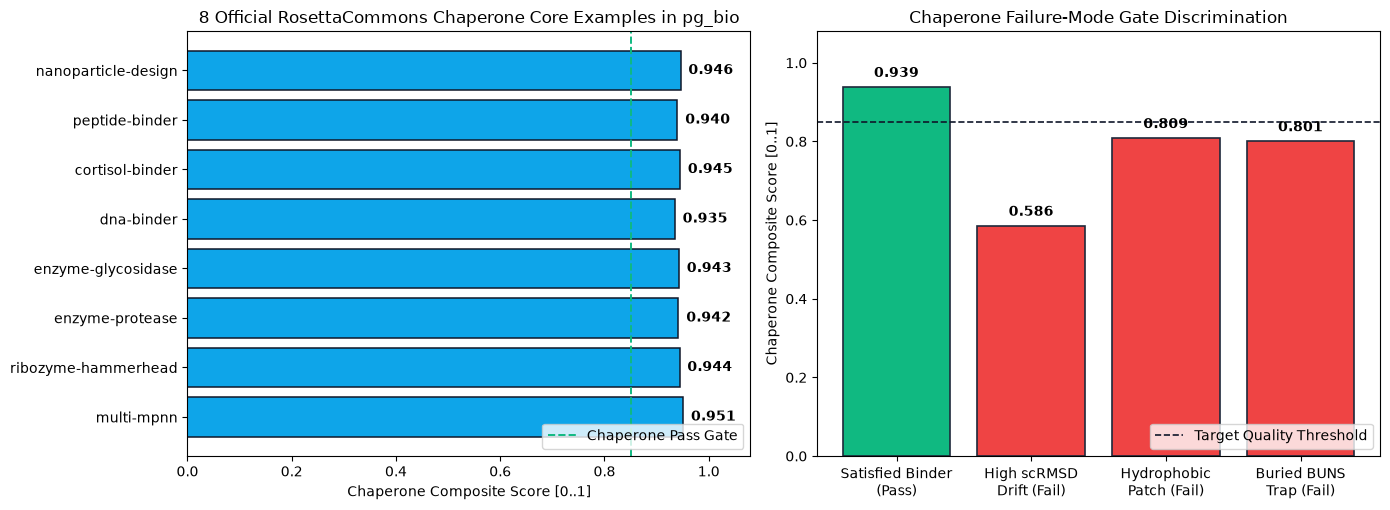

In [5]:
# 4. Visualize Official Chaperone Core Examples & Failure-Mode Gate Discrimination
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

ex_names = df_core_examples['example_name'].tolist()
ex_scores = df_core_examples['composite_score'].tolist()
axes[0].barh(ex_names, ex_scores, color='#0ea5e9', edgecolor='#0f172a', linewidth=1.1)
axes[0].axvline(0.85, color='#10b981', linestyle='--', linewidth=1.4, label='Chaperone Pass Gate')
axes[0].set_xlim(0, 1.08)
axes[0].set_xlabel('Chaperone Composite Score [0..1]')
axes[0].set_title('8 Official RosettaCommons Chaperone Core Examples in pg_bio')
axes[0].invert_yaxis()
axes[0].legend(loc='lower right')
for idx, val in enumerate(ex_scores):
    axes[0].text(val + 0.015, idx, f'{val:.3f}', va='center', fontweight='bold')

labels = ['Satisfied Binder\n(Pass)', 'High scRMSD\nDrift (Fail)', 'Hydrophobic\nPatch (Fail)', 'Buried BUNS\nTrap (Fail)']
scores = df_archetypes['composite_score'].tolist()
colors = ['#10b981' if p else '#ef4444' for p in df_archetypes['passes_gate']]

axes[1].bar(labels, scores, color=colors, edgecolor='#1e293b', linewidth=1.2)
axes[1].axhline(0.85, color='#0f172a', linestyle='--', linewidth=1.2, label='Target Quality Threshold')
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel('Chaperone Composite Score [0..1]')
axes[1].set_title('Chaperone Failure-Mode Gate Discrimination')
axes[1].legend(loc='lower right')
for idx, val in enumerate(scores):
    axes[1].text(idx, val + 0.025, f'{val:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()